# 05 · Evaluation and Optimisation
**Notebook 5 of 6:** brief tasks 5 (compare with ground truth, then fine-tune and optimise), 6 (automation) and 7 (documentation).

**The rule this notebook follows:** every tuning decision is made on the **74 training + 12 validation photos**. The **14 test photos** are touched only once, for the final scoreboard, so the reported numbers are an unbiased estimate (for these three report formats).

| Question | Metric |
|---|---|
| Does YOLO find the fields? | mAP on the test split + field recall at IoU ≥ 0.5, per layout |
| Does OCR read them correctly? | **exact match** per field (after ignoring spaces and case) and **CER** (character error rate) |
| Where do errors come from? | YOLO boxes vs. *oracle* (hand-checked) boxes, which separates detection error from OCR error |
| Is it safe to automate? | how many rows pass with no review, and how many of those are fully correct |

In [1]:
# --- 0. Paths: the same notebook runs in Google Colab (with Drive) or on a laptop ----------
import sys, os, subprocess, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

IN_COLAB = "google.colab" in sys.modules              # True when running inside Colab
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")                     # brief Task 1.1: mount Google Drive
    DRIVE = Path("/content/drive/MyDrive/Custom_OCR")  # datasets/, model/, results/ live here
    REPO = Path("/content/custom-ocr-lab-reports")     # the code (cloned from GitHub)
    if not REPO.exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/Subharshi1997/NextHikes-Project-9-MedicalReportReader.git", str(REPO)], check=True)
    subprocess.run("apt-get -qq install -y tesseract-ocr > /dev/null", shell=True)        # the OCR engine
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "-r", str(REPO / "requirements.txt")])
else:
    here = Path.cwd().resolve()
    REPO = here.parent if here.name == "notebooks" else here   # repo root on a local machine
    DRIVE = REPO                                               # locally, "Drive" = the repo folder

sys.path[:0] = [str(REPO), str(REPO / "tools")]   # so we can import Custom_OCR and the tools
import Custom_OCR; Custom_OCR.find_tesseract()      # finds Tesseract even when it is not on PATH (Windows)
DATASETS = DRIVE / "datasets"                     # brief folder structure: datasets/
RAW = DATASETS / "raw"                            # the 100 report photos (kept out of GitHub: they show a patient's name)
MODEL_DIR = DRIVE / "model"                       # brief: "a folder named model" for the weights
RESULTS = DRIVE / "results"                       # brief: results/
for p in (DATASETS, RAW, MODEL_DIR, RESULTS):
    p.mkdir(parents=True, exist_ok=True)
print("Code  :", REPO)
print("Data  :", DATASETS)
print("Colab :", IN_COLAB)

Code  : C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main
Data  : C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main\datasets
Colab : False


In [2]:
# --- 1. Libraries, model, annotations ----------------------------------------------------------
import json, dataclasses, cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
import Custom_OCR as co, evaluate as ev, viz
viz.style()
OUT = RESULTS / "05_evaluation"; OUT.mkdir(parents=True, exist_ok=True)
weights = MODEL_DIR / "best.pt" if (MODEL_DIR / "best.pt").exists() else REPO / "model" / "best.pt"
model = co.load_model(weights)
ann = ev.load_annotations(DATASETS / "annotations.json")
test = sorted(n for n, a in ann.items() if a["split"] == "test")
tune = sorted(n for n, a in ann.items() if a["split"] != "test")
print(f"tuning photos: {len(tune)} | test photos: {len(test)}")
pd.set_option("display.max_colwidth", 60); pd.set_option("display.width", 160)

tuning photos: 86 | test photos: 14


## Part 1 · Detection on the unseen test photos

In [3]:
# --- 1.1 Standard YOLO metrics on the test split ----------------------------------------------
m = model.val(data=str(DATASETS / "yolo" / "data.yaml"), split="test", imgsz=1024, batch=4, plots=False, verbose=False)
det = pd.DataFrame({"class": [model.names[i] for i in range(4)], "precision": m.box.p, "recall": m.box.r,
                    "mAP50": m.box.ap50, "mAP50-95": m.box.ap})
det.loc[len(det)] = ["ALL", m.box.mp, m.box.mr, m.box.map50, m.box.map]
det = det.round(3); det.to_csv(OUT / "test_detection_metrics.csv", index=False); det

Ultralytics 8.4.188  Python-3.11.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)


YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 164.8±70.5 MB/s, size: 57.4 KB)


val: Scanning C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main\datasets\yolo\labels\test... 14 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 14/14  0.0s

val: New cache created: C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main\datasets\yolo\labels\test.cache


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 75% ━━━━━━━━━─── 3/4 4.1it/s 2.2s<0.2s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.7it/s 2.3s

                   all         14        248      0.997      0.999      0.995      0.876


Speed: 2.2ms preprocess, 23.6ms inference, 0.0ms loss, 1.1ms postprocess per image


,class,precision,recall,mAP50,mAP50-95
0,test_name,1.000,0.998,0.995,0.823
1,value,0.995,1.000,0.995,0.862
2,unit,0.995,1.000,0.995,0.913
3,reference_range,0.997,1.000,0.995,0.905
4,ALL,0.997,0.999,0.995,0.876


In [4]:
# --- 1.2 Field recall per layout: did YOLO box each fully visible field (IoU >= 0.5)? ---------
rec = ev.detection_recall(model, RAW, ann, test)
recall_tab = rec.pivot_table(index="field", columns="layout", values="found", aggfunc="mean").mul(100).round(1)
recall_tab["ALL"] = rec.groupby("field").found.mean().mul(100).round(1)
recall_tab.loc["ALL"] = list(rec.groupby("layout").found.mean().mul(100).round(1)) + [round(rec.found.mean() * 100, 1)]
print(f"{int(rec.found.sum())} / {len(rec)} fields found  |  median IoU of found boxes {rec[rec.found].iou.median():.2f}")
recall_tab

222 / 222 fields found  |  median IoU of found boxes 0.94


layout,liver,thyroid,vitamin,ALL
field,,,,
reference_range,100.0,100.0,100.0,100.0
test_name,100.0,100.0,100.0,100.0
unit,100.0,100.0,100.0,100.0
value,100.0,100.0,100.0,100.0
ALL,100.0,100.0,100.0,100.0


## Part 2 · Optimising the OCR stage (tuning photos only)
`tools/tune_preprocessing.py` starts from the brief's exact recipe and changes **one knob at a time**, keeping a change only if field exact-match improves on the 86 tuning photos (oracle boxes, so detection cannot muddy the comparison). It takes about 15 minutes (run it with `--workers 8` to read photos in parallel), so the logged run is loaded here; set `RERUN = True` to repeat it.

In [5]:
# --- 2.1 Load (or rerun) the ablation ------------------------------------------------------
RERUN = False
if RERUN or not (OUT / "ablation_log.csv").exists():
    import tune_preprocessing; tune_preprocessing.main(RAW, OUT)
abl = pd.read_csv(OUT / "ablation_log.csv")
abl["label"] = abl.apply(lambda r: "brief recipe" if r.step == 0 else f"{r.knob} = {r.value}", axis=1)
abl[["step", "label", "exact_match", "mean_cer", "kept"]].assign(exact_match=lambda d: (d.exact_match * 100).round(1),
                                                                mean_cer=lambda d: d.mean_cer.round(3))

,step,label,exact_match,mean_cer,kept
0,0,brief recipe,67.9,0.125,True
1,1,psm_single = 7,63.9,0.152,False
2,2,psm_single = 13,32.0,0.284,False
3,3,border = 10,68.0,0.129,True
4,4,interp = cubic,70.7,0.115,True
5,5,blur = 3,70.7,0.108,True
6,6,blur = 0,71.4,0.104,True
7,7,binarize = False,31.1,0.355,False
8,8,scale = 2.0,68.3,0.116,False
9,9,scale = 4.0,71.1,0.107,False


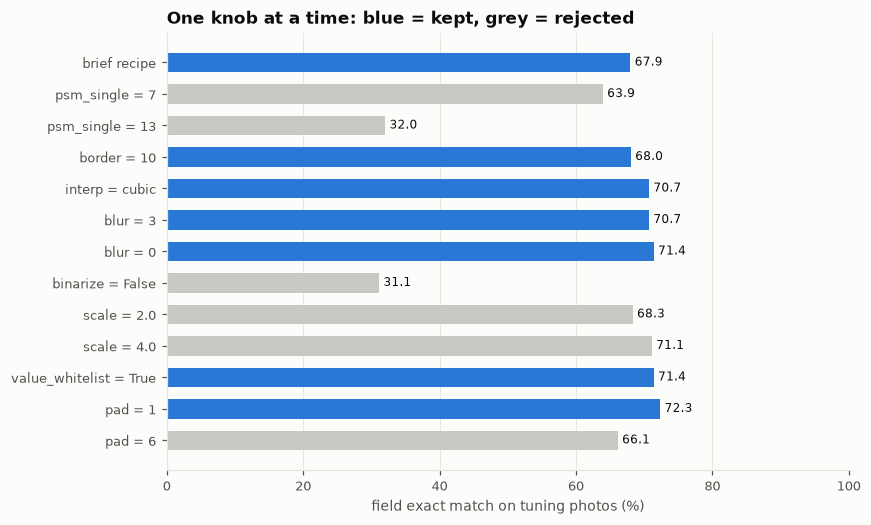

{'scale': 3.0,
 'interp': 'cubic',
 'blur': 0,
 'binarize': True,
 'border': 10,
 'psm_single': 6,
 'psm_multi': 6,
 'value_whitelist': True,
 'pad': 1,
 'unit_lexicon': False}

In [6]:
# --- 2.2 Chart: every change tried, kept changes highlighted ---------------------------------
fig, ax = plt.subplots(figsize=(8, 0.32 * len(abl) + 1))
colors = [viz.SERIES[0] if k else "#c9c8c3" for k in abl.kept]
bars = ax.barh(range(len(abl))[::-1], abl.exact_match * 100, color=colors, height=0.62)
ax.set_yticks(range(len(abl))[::-1], abl.label); ax.set_xlim(0, 100); ax.set_axisbelow(True)
ax.set_xlabel("field exact match on tuning photos (%)")
ax.set_title("One knob at a time: blue = kept, grey = rejected")
viz.hbar_labels(ax, bars, "{:.1f}"); ax.grid(axis="y", visible=False)
fig.savefig(OUT / "ablation.png"); plt.show()
best_cfg = json.load(open(OUT / "best_preprocessing.json")); best_cfg

### A second, separate improvement: a unit lexicon
Most remaining errors are in **units**, and they are classic OCR confusions: `dl` read as `di`, `µ` read as `p`, `y` or `v`, and `l` read as `\` or `!`. Units on lab reports come from a short, closed vocabulary. `snap_unit()` therefore matches the OCR text to a list of ~40 **generic clinical units**, using an edit distance in which visually confusable characters (l/i/1, g/q/a, µ/u/p/y…) are cheap to swap. It replaces the text **only** when one unit is clearly closest; otherwise the raw text is kept and the row can be flagged.

The lexicon is generic rather than copied from this dataset, but it includes the units these reports use, so its benefit would be smaller on reports with unusual units. We therefore report results **with and without** it.

## Part 3 · Final scoreboard on the 14 unseen test photos
| configuration | boxes | preprocessing | unit lexicon |
|---|---|---|---|
| **A** brief, oracle boxes | hand-checked | brief | no |
| **B** tuned, oracle boxes | hand-checked | tuned | no |
| **C** brief pipeline (as specified) | YOLO | brief | no |
| **D** tuned pipeline | YOLO | tuned | no |
| **E** tuned + lexicon (shipped default) | YOLO | tuned | yes |

In [7]:
# --- 3.1 Score all five configurations ---------------------------------------------------------
TUNED_NOLEX = dataclasses.replace(co.TUNED, unit_lexicon=False, name="tuned_nolex")
runs = {}
runs["A brief + oracle boxes"] = ev.score_oracle(RAW, ann, test, co.BRIEF)
runs["B tuned + oracle boxes"] = ev.score_oracle(RAW, ann, test, TUNED_NOLEX)
runs["C brief pipeline (YOLO)"], _ = ev.score_end_to_end(RAW, ann, test, co.BRIEF, model)
runs["D tuned pipeline (YOLO)"], _ = ev.score_end_to_end(RAW, ann, test, TUNED_NOLEX, model)
runs["E tuned + unit lexicon (YOLO)"], preds_final = ev.score_end_to_end(RAW, ann, test, co.TUNED, model)

board = pd.DataFrame({k: ev.summary(v)["exact_match"] for k, v in runs.items()}).T
board["mean CER"] = [round(v.cer.mean(), 3) for v in runs.values()]
board = board[["test_name", "value", "unit", "reference_range", "ALL", "mean CER"]]
board.to_csv(OUT / "test_scoreboard.csv"); board

field,test_name,value,unit,reference_range,ALL,mean CER
A brief + oracle boxes,82.5,88.7,21.0,82.8,67.1,0.133
B tuned + oracle boxes,92.5,93.5,21.0,86.2,71.2,0.105
C brief pipeline (YOLO),82.5,91.9,21.0,82.8,68.0,0.135
D tuned pipeline (YOLO),87.5,93.5,21.0,86.2,70.3,0.107
E tuned + unit lexicon (YOLO),87.5,93.5,88.7,86.2,89.2,0.036


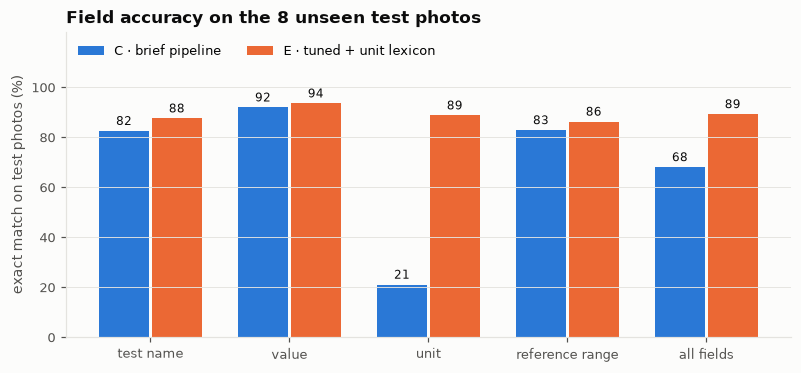

In [8]:
# --- 3.2 Chart: the brief pipeline vs the shipped pipeline, per field ------------------------
fields = ["test_name", "value", "unit", "reference_range", "ALL"]
c_, e_ = board.loc["C brief pipeline (YOLO)", fields], board.loc["E tuned + unit lexicon (YOLO)", fields]
x = np.arange(len(fields)); w = 0.36
fig, ax = plt.subplots(figsize=(8.5, 3.6))
b1 = ax.bar(x - w / 2 - 0.01, c_, w, color=viz.SERIES[0], label="C · brief pipeline")
b2 = ax.bar(x + w / 2 + 0.01, e_, w, color=viz.SERIES[1], label="E · tuned + unit lexicon")
viz.bar_labels(ax, b1, "{:.0f}"); viz.bar_labels(ax, b2, "{:.0f}")
ax.set_xticks(x, ["test name", "value", "unit", "reference range", "all fields"]); ax.set_ylim(0, 122); ax.set_yticks(range(0, 101, 20))
ax.set_ylabel("exact match on test photos (%)"); ax.set_title("Field accuracy on the 8 unseen test photos")
ax.legend(loc="upper left", ncol=2); ax.grid(axis="x", visible=False)
fig.savefig(OUT / "scoreboard.png"); plt.show()

In [9]:
# --- 3.3 Final pipeline by layout ---------------------------------------------------------------
final = runs["E tuned + unit lexicon (YOLO)"]
by_layout = final.pivot_table(index="field", columns="layout", values="exact", aggfunc="mean").mul(100).round(1)
by_layout.loc["ALL"] = final.groupby("layout").exact.mean().mul(100).round(1)
by_layout.to_csv(OUT / "final_by_layout.csv"); by_layout

layout,liver,thyroid,vitamin
field,,,
reference_range,90.9,95.2,0.0
test_name,90.9,33.3,100.0
unit,90.9,95.2,62.5
value,100.0,100.0,50.0
ALL,93.2,93.9,54.2


In [10]:
# --- 3.4 Context: Tesseract on the whole page, no YOLO --------------------------------------
fp = ev.full_page_baseline(RAW, ann, test)
print(f"Full-page Tesseract: {fp.found_somewhere.mean():.0%} of true values appear *somewhere* in the page text,")
print("but with no row/column structure: nothing says which number belongs to which test or unit.")

Full-page Tesseract: 74% of true values appear *somewhere* in the page text,
but with no row/column structure: nothing says which number belongs to which test or unit.


## Part 3b · YOLOv3 (the brief's model) vs YOLO26n, end to end
The scoreboard above uses the shipped detector (`model/best.pt`). Here **both** detectors from notebook 03 run through the identical OCR stage on the same unseen test photos: detection quality (mAP, field recall), the final CSV accuracy with the brief's preprocessing (C) and with the shipped settings (E), and cost (size, seconds per photo on this machine).

In [11]:
# --- 3b.1 Head-to-head on the test photos ------------------------------------------------------
import compare_detectors as cd
RERUN_COMPARE = False
if RERUN_COMPARE or not (OUT / "detector_comparison.csv").exists():
    cd.compare([MODEL_DIR / "yolov3u_best.pt", MODEL_DIR / "yolo26n_best.pt"], RAW, OUT)
cmp_df = pd.read_csv(OUT / "detector_comparison.csv").set_index("detector")
cmp_df

Ultralytics 8.4.188  Python-3.11.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)


YOLOv3 summary (fused): 96 layers, 103,667,324 parameters, 0 gradients, 282.2 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 1077.9±168.2 MB/s, size: 57.6 KB)


val: Scanning C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main\datasets\yolo\labels\test.cache... 14 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 14/14  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 25% ━━━───────── 1/4 9.1s/it 2.7s<27.2s

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.8it/s 2.2s

                   all         14        248      0.997      0.999      0.995      0.876


Speed: 2.4ms preprocess, 18.9ms inference, 0.0ms loss, 1.0ms postprocess per image


{'detector': 'yolo26n', 'params_M': 2.5, 'weights_MB': 5.5, 'test_mAP50': 0.995, 'test_mAP50_95': 0.876, 'field_recall_iou50': np.float64(1.0), 'exact_brief_C': np.float64(68.0), 'exact_shipped_E': np.float64(89.2), 'cer_shipped_E': np.float64(0.036), 'value_exact_E': np.float64(93.5), 'sec_per_photo': 2.31, 'test_photos': 14, 'fields': 222}


,params_M,weights_MB,test_mAP50,test_mAP50_95,field_recall_iou50,exact_brief_C,exact_shipped_E,cer_shipped_E,value_exact_E,sec_per_photo,test_photos,fields
detector,,,,,,,,,,,,
yolov3u,103.7,207.8,0.994,0.806,1.0,62.2,82.9,0.078,88.7,2.24,14,222
yolo26n,2.5,5.5,0.995,0.876,1.0,68.0,89.2,0.036,93.5,2.31,14,222


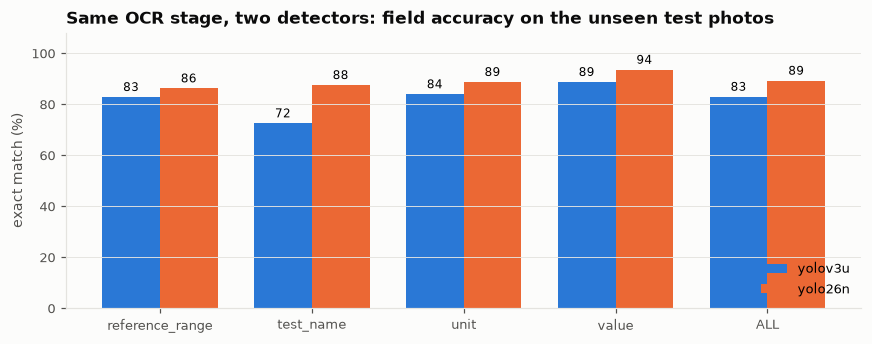

In [12]:
# --- 3b.2 Chart: exact match per field, both detectors (shipped settings E) ---------------------
byf = pd.read_csv(OUT / "detector_comparison_by_field.csv", index_col=0)
fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(byf.index)); w = 0.38
for k, name in enumerate(byf.columns):
    bars = ax.bar(x + (k - 0.5) * w, byf[name], w, color=viz.SERIES[k], label=name)
    ax.bar_label(bars, fmt="%.0f", fontsize=8, padding=2)
ax.set_xticks(x, byf.index); ax.set_ylim(0, 108); ax.set_ylabel("exact match (%)")
ax.set_title("Same OCR stage, two detectors: field accuracy on the unseen test photos"); ax.legend(loc="lower right")
ax.grid(axis="x", visible=False)
plt.tight_layout(); fig.savefig(OUT / "detector_comparison.png"); plt.show()

## Part 4 · Error analysis: what is still wrong?

In [13]:
# --- 4.1 Every remaining error of the shipped pipeline --------------------------------------
err = final[~final.exact].copy()
err["CER"] = err.cer.round(2)
print(f"{len(err)} wrong fields out of {len(final)}")
err[["image", "layout", "field", "truth", "pred", "CER"]].sort_values(["field", "layout"])

24 wrong fields out of 222


,image,layout,field,truth,pred,CER
41,thyrocare_0_3558.jpg,liver,reference_range,< 0.3,<0O.%,0.50
106,thyrocare_0_4979.jpg,liver,reference_range,< 0.3,<0.,0.25
154,thyrocare_0_5640.jpg,liver,reference_range,< 0.3,<O.%,0.50
212,thyrocare_0_9108.jpg,thyroid,reference_range,0.3-5.5,0.3-S.5,0.14
81,thyrocare_0_4046.jpg,vitamin,reference_range,DEFICIENCY : <20 ng/ml | INSUFFICIENCY : 20-<30 ng/ml | ...,DEFICIENCY 20 ng/mi | INSUFFICIENCY . 20-<30 ng/mi | SUF...,0.14
85,thyrocare_0_4046.jpg,vitamin,reference_range,Normal : 211 - 911 pg/ml,Woemal : 231 - 91 poym,0.37
190,thyrocare_0_5928.jpg,vitamin,reference_range,DEFICIENCY : <20 ng/ml | INSUFFICIENCY : 20-<30 ng/ml | ...,DEFICIENCY | <20 ngiirs | INSUFFIQIENCY ; 20-<30 ng/mi |...,0.16
194,thyrocare_0_5928.jpg,vitamin,reference_range,Normal : 211 - 911 pg/ml,Mormal ; 21t - 911 poym,0.32
135,thyrocare_0_4979.jpg,liver,test_name,SERUM GLOBULIN,SERUM GLOBULIN:,0.08
159,thyrocare_0_5640.jpg,liver,test_name,GAMMA GLUTAMYL TRANSFERASE (GGT),GAMMA GLUTAMYL TRANSFERASE (GG1I),0.07


## Part 5 · Is it safe to automate? (the review flag)
A lab does not need 100% automation; it needs **no silent errors**. We check every predicted row:
- **straight-through**: not flagged, so it goes into the system without a human;
- **error escape**: straight-through but at least one field wrong. This is the number to minimise.

In [14]:
# --- 5.1 Row-level view ---------------------------------------------------------------------------
rows = final.groupby(["image", "row"]).agg(all_correct=("exact", "all"), flagged=("needs_review", "first")).reset_index()
tab = pd.crosstab(rows.flagged.map({True: "flagged for review", False: "straight-through"}),
                  rows.all_correct.map({True: "all fields correct", False: "has an error"}), margins=True)
st = rows[~rows.flagged]
print(f"Rows: {len(rows)} | straight-through: {len(st)} ({len(st) / len(rows):.0%}) | "
      f"straight-through accuracy: {st.all_correct.mean():.0%} | errors caught by the flag: "
      f"{(rows.flagged & ~rows.all_correct).sum()} of {(~rows.all_correct).sum()}")
tab

Rows: 62 | straight-through: 12 (19%) | straight-through accuracy: 92% | errors caught by the flag: 18 of 19


all_correct,all fields correct,has an error,All
flagged,,,
flagged for review,32,18,50
straight-through,11,1,12
All,43,19,62


In [15]:
# --- 5.2 Spurious rows: a false-positive test-name box creates a row that does not exist ----
spur = ev.spurious_rows(preds_final, ann)
print(f"Spurious rows (no matching real test): {len(spur)} | of these flagged for review: "
      f"{int(spur.needs_review.sum()) if len(spur) else 0}")
spur

Spurious rows (no matching real test): 0 | of these flagged for review: 0


,image,test_name,value,needs_review,review_reason


## Part 6 · Business view (estimates, clearly labelled)
These figures are **assumptions for illustration**, not measurements. They show how the metrics above would be used in a decision.

In [16]:
# --- 6.1 Time per photo (measured) and a labelled estimate of manual effort saved ----------------
import time
t0 = time.time()
for n in test:
    co.run_image(model, RAW / n, co.TUNED)
sec_per_photo = (time.time() - t0) / len(test)
ASSUMED_SECONDS_PER_ROW_MANUAL = 25        # ASSUMPTION: typing 4 fields of one test by hand
ASSUMED_SECONDS_PER_ROW_REVIEW = 8         # ASSUMPTION: checking one flagged row against the photo
rows_per_photo = len(rows) / len(test)
manual = rows_per_photo * ASSUMED_SECONDS_PER_ROW_MANUAL
assisted = sec_per_photo + rows_per_photo * rows.flagged.mean() * ASSUMED_SECONDS_PER_ROW_REVIEW
print(f"Measured pipeline time: {sec_per_photo:.1f} s per photo on this machine (CPU)")
print(f"ESTIMATE: manual {manual:.0f} s vs assisted {assisted:.0f} s per photo -> about {1 - assisted / manual:.0%} less effort")

Measured pipeline time: 2.2 s per photo on this machine (CPU)
ESTIMATE: manual 111 s vs assisted 31 s per photo -> about 72% less effort


In [17]:
# --- 6.2 Save a machine-readable summary for the README and report -----------------------
import filecmp
shipped = next((n for n in ("yolov3u", "yolo26n") if (MODEL_DIR / f"{n}_best.pt").exists()
                and filecmp.cmp(weights, MODEL_DIR / f"{n}_best.pt", shallow=False)), Path(weights).stem)
summary = {
    "detector": shipped, "test_photos": len(test),
    "detection_test_mAP50": float(m.box.map50), "detection_test_mAP50_95": float(m.box.map),
    "field_recall_iou50": float(rec.found.mean()),
    "exact_match": {k: float(v["exact"].mean()) for k, v in runs.items()},
    "mean_cer": {k: float(v["cer"].mean()) for k, v in runs.items()},
    "final_by_field": final.groupby("field").exact.mean().round(4).to_dict(),
    "final_by_layout": final.groupby("layout").exact.mean().round(4).to_dict(),
    "rows": int(len(rows)), "straight_through_rate": float((~rows.flagged).mean()),
    "straight_through_accuracy": float(st.all_correct.mean()) if len(st) else None,
    "errors_caught_by_flag": int((rows.flagged & ~rows.all_correct).sum()), "rows_with_errors": int((~rows.all_correct).sum()),
    "spurious_rows": int(len(spur)), "spurious_rows_flagged": int(spur.needs_review.sum()) if len(spur) else 0,
    "full_page_values_found": float(fp.found_somewhere.mean()), "seconds_per_photo_cpu": round(sec_per_photo, 2),
    "tuned_preprocessing": best_cfg,
}
json.dump(summary, open(OUT / "summary.json", "w"), indent=1)
final.to_csv(OUT / "final_field_scores.csv", index=False)
summary["exact_match"]

{'A brief + oracle boxes': 0.6711711711711712,
 'B tuned + oracle boxes': 0.7117117117117117,
 'C brief pipeline (YOLO)': 0.6801801801801802,
 'D tuned pipeline (YOLO)': 0.7027027027027027,
 'E tuned + unit lexicon (YOLO)': 0.8918918918918919}

## Part 7 · Automation and deployment (brief section 6)
- **Batch mode:** `python Custom_OCR.py --image <folder> --excel` processes every image in a folder and writes one CSV (and .xlsx) per photo plus `all_reports.csv`. Pointed at a Drive folder from a scheduled Colab run, or at a watched folder via cron, that is a working intake pipeline at $0.
- **Web app + API:** `uvicorn app.server:app` serves an upload page (annotated photo, editable table, CSV/Excel download) and a JSON API at `/api/ocr`.
- **Docker:** one image (`Dockerfile`) runs the web app (`serve`), the batch CLI (`ocr`) and SageMaker training (`train`).
- **AWS:** the same image is a SageMaker serverless endpoint (`/ping` + `/invocations`) and a SageMaker Processing job that OCRs an S3 folder into CSVs; see **notebook 06** and `aws/`.
- **Human-in-the-loop:** rows with `needs_review = True` go to a person; the rest are loaded directly.
- **Cost:** Colab free tier + Google Drive (under 15 GB), so **$0**, as the brief estimates. Inference takes about 2 s per photo (mostly Tesseract), so no GPU is needed in production. On AWS, a serverless SageMaker endpoint costs nothing while idle (notebook 06).

## Limitations (stated plainly)
1. **Three documents.** All splits contain the same three report designs, so the scores measure robustness to *photo conditions*, not to *new layouts*. A new lab format needs roughly 5-10 annotated photos.
2. **Small test set.** 14 photos = 222 scored fields. One field is about 0.45 points of exact match, so treat differences under ~2-3 points as noise. Some fields are rarely scored: most thyroid photos crop the test names at the frame edge, so only 3 thyroid test names are fully visible (and scored) in the test set.
3. **Tesseract on tiny print.** The vitamin page (6-8 px text) is the weak spot: YOLO finds every field, but Tesseract misreads 4 of its 8 test *values* (551 read as 351 or 552, 21 as 2 or 22) and never gets the four-line reference range exactly right. **All 4 misread values are flagged for review**, so none would be loaded silently, but this is the clinically important gap. A stronger OCR engine (PaddleOCR, or a fine-tuned TrOCR) on value crops is the next lever.
4. **The unit lexicon** helps because units come from a closed vocabulary; results without it are reported alongside.

## What I would do next
- Collect 20-30 photos of *other* labs' reports and measure true layout generalisation.
- Fine-tune Tesseract (or swap in PaddleOCR) on value and unit crops; values carry the clinical risk.
- Add numeric sanity checks: a value outside 10× the reference range triggers review.

**Mentor check**
1. Why are oracle-box scores useful even though no user will ever have oracle boxes?
2. Which single number would you show a lab director, and why?
3. Why does the review-flag analysis matter more than overall exact match?